# 07 – Finding 4: why are 21–24-year-olds rejected more?
Notebook 05 showed young applicants are rejected more. Is that a plain age penalty, or something more
specific? We only use applicants whose job history is realistic for a young person.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from common import BLUE, ORANGE, finish_chart, load_data, sweep, what_if

df = load_data()

## 1. Change only age
Applicants approved at 25 with ≤ 3 years in their job.

In [2]:
young_ok = df[df.employment_years <= 3]
_, rejected = what_if(young_ok, age=25)
table = sweep(young_ok[~rejected], "age", range(21, 31))
table

,age,reject_rate,avg_risk
0,21,0.450,0.465
1,22,0.450,0.464
2,23,0.450,0.464
3,24,0.450,0.425
4,25,0.000,0.026
5,26,0.000,0.013
6,27,0.000,0.014
7,28,0.012,0.019
8,29,0.025,0.023
9,30,0.025,0.024


A hard cut at 25: 45% rejected at every age from 21 to 24, and 0% at 25. Looking at **who** was
rejected, they were all on 48- or 60-month loans with short job histories. The next test checks that.

## 2. Age × tenure × years in job, every combination, same applicants each time

In [3]:
pool = df[df.employment_years <= 6]
_, rejected = what_if(pool, age=25)
approved = pool[~rejected]
print("Approved at age 25:", len(approved))

rows = []
for tenure in [36, 48, 60]:
    for emp in [2, 4, 5]:
        row = {"tenure_months": tenure, "employment_years": emp}
        for age in [22, 24, 25, 26]:
            _, r = what_if(approved, age=age, tenure_months=tenure, employment_years=emp)
            row[f"reject_at_age_{age}"] = round(r.mean(), 3)
        rows.append(row)
table = pd.DataFrame(rows)
table

Approved at age 25: 136


,tenure_months,employment_years,reject_at_age_22,reject_at_age_24,reject_at_age_25,reject_at_age_26
0,36,2,0.051,0.051,0.051,0.051
1,36,4,0.037,0.029,0.029,0.029
2,36,5,0.037,0.015,0.015,0.015
3,48,2,1.000,0.978,0.044,0.022
4,48,4,1.000,0.978,0.044,0.015
5,48,5,1.000,0.066,0.007,0.000
6,60,2,1.000,0.985,0.015,0.000
7,60,4,1.000,0.993,0.015,0.000
8,60,5,1.000,0.022,0.000,0.000


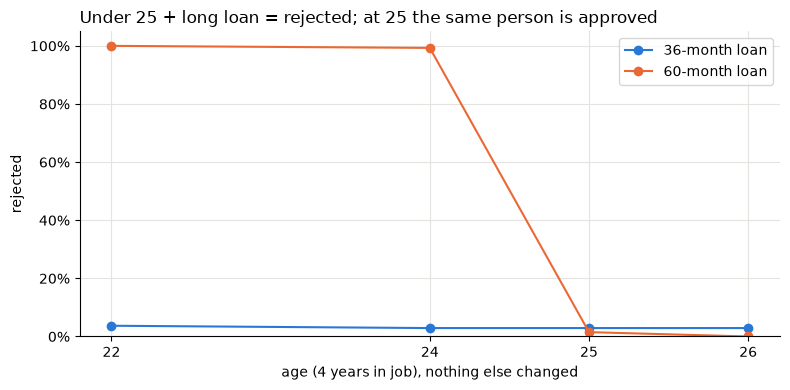

In [4]:
ages = [22, 24, 25, 26]
fig, ax = plt.subplots(figsize=(8, 4))
for tenure, color in [(36, BLUE), (60, ORANGE)]:
    row = table[(table.tenure_months == tenure) & (table.employment_years == 4)].iloc[0]
    ax.plot(ages, [row[f"reject_at_age_{a}"] for a in ages], "o-", color=color, label=f"{tenure}-month loan")
ax.set_xticks(ages)
ax.set_xlabel("age (4 years in job), nothing else changed")
ax.legend()
finish_chart(ax, "Under 25 + long loan = rejected; at 25 the same person is approved", "fig4_age_tenure.png")

## 3. Is the same rule in the old decisions?

In [5]:
df["label_rejected"] = df.decision == "reject"
rule = (df.age < 25) & (df.tenure_months >= 48) & (df.employment_years <= 4)
print(f"Matching the rule: {rule.sum()} applicants, {df.label_rejected[rule].mean():.0%} rejected")
print(f"Everyone else: {df.label_rejected[~rule].mean():.1%} rejected")

Matching the rule: 25 applicants, 100% rejected
Everyone else: 57.6% rejected


**Conclusion:** it is **not** a simple age penalty (that idea was false). The model rejects
applicants who are **under 25 AND ask for a 48/60-month loan AND have ≤ 4 years in their job**. The same
person at 25 is approved. All 25 such applicants in the old decisions were rejected.